# Task 5.1 - Calibration Evaluation

This evaluates the unchanged selected Task 4.3 80% context-XGBoost / 20% MC OOF ensemble across 560 fixtures. No recalibration occurs here; calibration diagnostics are required before turning probabilities into betting decisions.

In [1]:
# Load configuration and imports
%load_ext autoreload
%autoreload 2
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd()
while repo_root != repo_root.parent and not (repo_root / "src" / "config" / "loader.py").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.evaluation.calibration import (
    PROBABILITY_COLUMNS,
    build_calibration_report,
    compute_chronological_brier_trend,
    save_calibration_artifacts,
    validate_selected_ensemble_frame,
)

processed_dir = repo_root / "data" / "processed"
ensemble_path = processed_dir / "ensemble_probabilities.parquet"
report_path = processed_dir / "task_4_3_evaluation_report.parquet"
assert ensemble_path.exists(), f"Selected ensemble artifact missing: {ensemble_path}"
predictions = pd.read_parquet(ensemble_path)
predictions = validate_selected_ensemble_frame(predictions)
print(predictions.info())
print(f"Validated {len(predictions)} selected OOF fixtures")
print(f"Date range: {predictions['date'].min()} to {predictions['date'].max()}")
print(f"Candidate: {predictions['selected_candidate'].iloc[0]}")
print(f"Weights: XGBoost={predictions['selected_xgb_weight'].iloc[0]:.2f}, MC={predictions['selected_mc_weight'].iloc[0]:.2f}")
print("Actual class rates:")
print(predictions["target_encoded"].value_counts(normalize=True).sort_index())

<class 'pandas.DataFrame'>
RangeIndex: 560 entries, 0 to 559
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   fixture_id              560 non-null    str           
 1   date                    560 non-null    datetime64[us]
 2   target_encoded          560 non-null    int64         
 3   ensemble_prob_home_win  560 non-null    float64       
 4   ensemble_prob_draw      560 non-null    float64       
 5   ensemble_prob_away_win  560 non-null    float64       
 6   selected_candidate      560 non-null    str           
 7   selected_xgb_weight     560 non-null    float64       
 8   selected_mc_weight      560 non-null    float64       
dtypes: datetime64[us](1), float64(5), int64(1), str(2)
memory usage: 51.0 KB
None
Validated 560 selected OOF fixtures
Date range: 2025-01-14 00:00:00 to 2026-05-24 00:00:00
Candidate: blend_context
Weights: XGBoost=0.80, MC=0.20
Actual class rate

## Overall Pre-Calibration Metrics

In [2]:
overall_metrics, per_class_summary, reliability_data = build_calibration_report(predictions)
trend = compute_chronological_brier_trend(predictions)
display(overall_metrics)
reference = {"multiclass_brier_score": 0.612993, "log_loss": 1.023682, "accuracy": 0.507143}
for metric, expected in reference.items():
    actual = float(overall_metrics.loc[0, metric])
    assert abs(actual - expected) <= 1e-6, f"{metric} mismatch: {actual} vs {expected}"
print("Brier and log loss are the primary proper scoring rules; calibration diagnostics are complementary.")

,selected_candidate,selected_xgb_weight,selected_mc_weight,oof_fixture_count,start_date,end_date,multiclass_brier_score,log_loss,accuracy,macro_expected_calibration_error,home_win_ece,draw_ece,away_win_ece,calibration_bin_count,evaluation_scope
0,blend_context,0.8,0.2,560,2025-01-14,2026-05-24,0.612993,1.023682,0.507143,0.031986,0.040462,0.025098,0.030397,30,oof_pre_calibration


Brier and log loss are the primary proper scoring rules; calibration diagnostics are complementary.


## Per-Class Calibration Diagnostics

In [3]:
display(per_class_summary)
print("Calibration compares predicted probability with observed event frequency. ECE is diagnostic, not a replacement for Brier/log loss.")
print("Draw probabilities may have sparser bins because draws are less frequent.")
print("This is descriptive across the same OOF history, not an independent final holdout test.")

,class_index,class_label,fixture_count,actual_event_rate,mean_predicted_probability,binary_brier_score,expected_calibration_error,max_absolute_calibration_gap,non_empty_bin_count,empty_bin_count,selected_candidate,selected_xgb_weight,selected_mc_weight,evaluation_scope
0,0,home_win,560,0.425,0.407467,0.223219,0.040462,0.294157,7,3,blend_context,0.8,0.2,oof_pre_calibration
1,1,draw,560,0.250,0.242565,0.189094,0.025098,0.428020,4,6,blend_context,0.8,0.2,oof_pre_calibration
2,2,away_win,560,0.325,0.349968,0.200680,0.030397,0.205291,7,3,blend_context,0.8,0.2,oof_pre_calibration


Calibration compares predicted probability with observed event frequency. ECE is diagnostic, not a replacement for Brier/log loss.
Draw probabilities may have sparser bins because draws are less frequent.
This is descriptive across the same OOF history, not an independent final holdout test.


## Reliability Diagrams

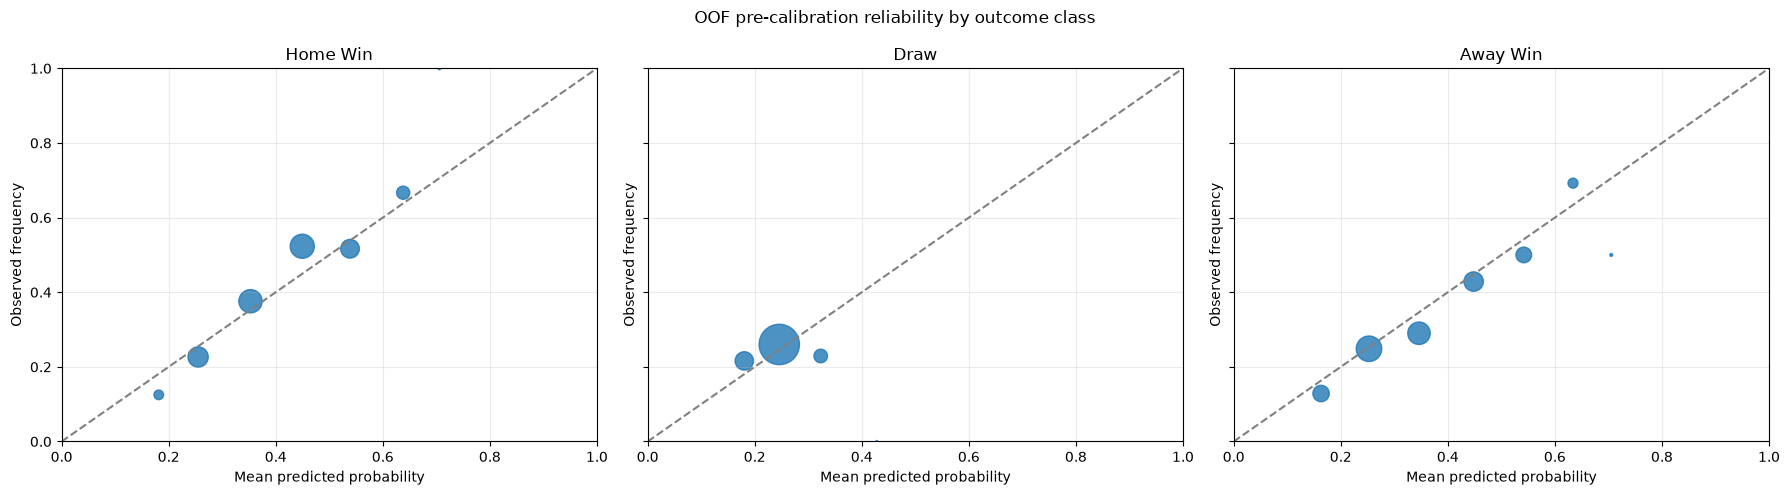

Empty-bin counts:


,class_label,empty_bin_count
0,home_win,3
1,draw,6
2,away_win,3


In [4]:
figure, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for axis, class_index in zip(axes, range(3)):
    table = reliability_data[reliability_data["class_index"] == class_index]
    non_empty = table[table["fixture_count"] > 0]
    axis.plot([0, 1], [0, 1], "--", color="gray")
    axis.scatter(non_empty["mean_predicted_probability"], non_empty["observed_frequency"], s=non_empty["fixture_count"] * 2, alpha=0.8)
    axis.set_title(class_index and ("Draw" if class_index == 1 else "Away Win") or "Home Win")
    axis.set_xlim(0, 1); axis.set_ylim(0, 1)
    axis.set_xlabel("Mean predicted probability"); axis.set_ylabel("Observed frequency")
    axis.grid(alpha=0.25)
figure.suptitle("OOF pre-calibration reliability by outcome class")
figure.tight_layout()
plt.show()
print("Empty-bin counts:")
display(per_class_summary[["class_label", "empty_bin_count"]])

## Chronological Probability Quality

Monthly samples may be small; this plot detects sustained drift, not statistically conclusive movement in an individual month.

,period,fixture_count,start_date,end_date,multiclass_brier_score,log_loss,accuracy
0,2025-01-01,29,2025-01-14,2025-01-26,0.565093,0.960137,0.586207
1,2025-02-01,42,2025-02-01,2025-02-27,0.580559,0.983613,0.523810
2,2025-03-01,18,2025-03-08,2025-03-16,0.583243,0.983900,0.500000
3,2025-04-01,50,2025-04-01,2025-04-27,0.589474,0.987442,0.500000
4,2025-05-01,41,2025-05-01,2025-05-25,0.618581,1.034832,0.512195
5,2025-08-01,30,2025-08-15,2025-08-31,0.638891,1.061192,0.533333
6,2025-09-01,30,2025-09-13,2025-09-29,0.651763,1.069825,0.433333
7,2025-10-01,30,2025-10-03,2025-10-26,0.501085,0.865126,0.666667
8,2025-11-01,40,2025-11-01,2025-11-30,0.584633,0.984384,0.575000
9,2025-12-01,56,2025-12-02,2025-12-30,0.599013,0.998973,0.517857


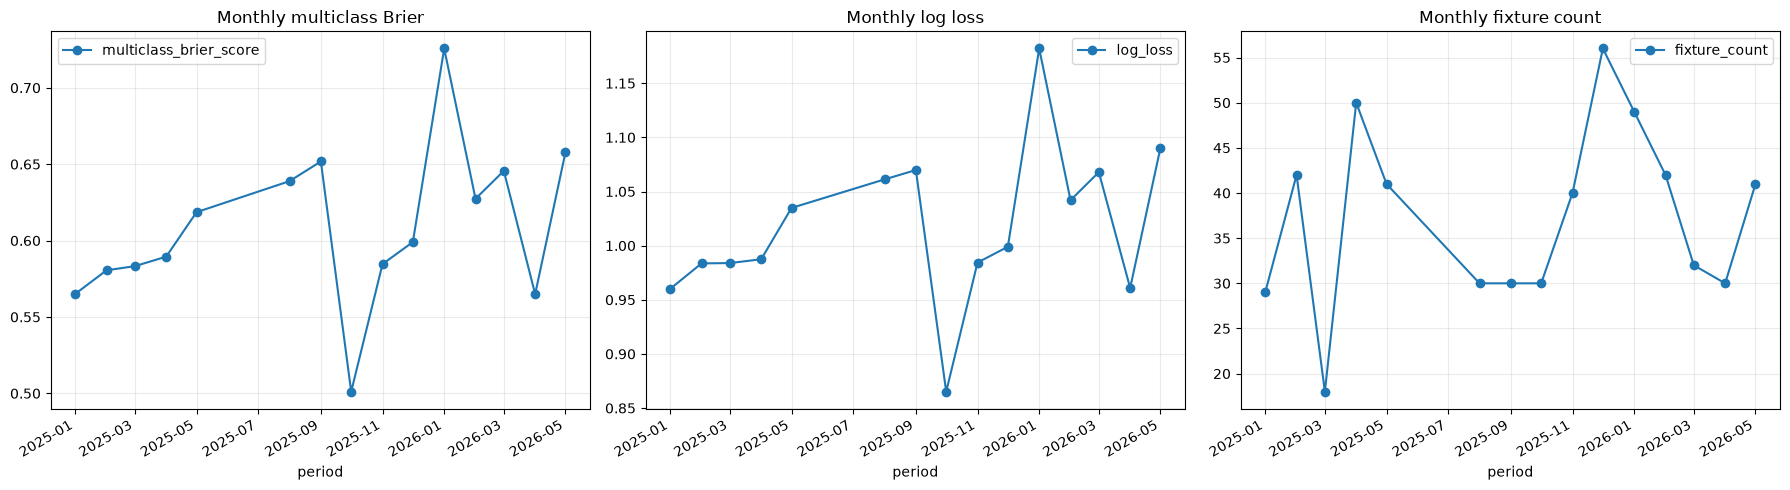

In [5]:
display(trend)
figure, axes = plt.subplots(1, 3, figsize=(18, 5))
trend.plot(x="period", y="multiclass_brier_score", ax=axes[0], marker="o", title="Monthly multiclass Brier")
trend.plot(x="period", y="log_loss", ax=axes[1], marker="o", title="Monthly log loss")
trend.plot(x="period", y="fixture_count", ax=axes[2], marker="o", title="Monthly fixture count")
for axis in axes: axis.grid(alpha=0.25)
figure.tight_layout()
plt.show()

## Save Calibration Evaluation Artifacts

In [6]:
paths = save_calibration_artifacts(overall_metrics, per_class_summary, reliability_data, trend, processed_dir)
for name, path in paths.items():
    saved = pd.read_parquet(path)
    print(name, path, saved.shape)
    display(saved.head())
assert len(pd.read_parquet(paths["calibration_metrics"])) == 4
assert len(pd.read_parquet(paths["reliability_diagram_data"])) == 30
assert pd.read_parquet(paths["brier_score_trend"])["fixture_count"].sum() == 560
print("No probabilities were transformed or overwritten.")

calibration_metrics /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/calibration_metrics.parquet (4, 26)


,selected_candidate,selected_xgb_weight,selected_mc_weight,oof_fixture_count,start_date,end_date,multiclass_brier_score,log_loss,accuracy,macro_expected_calibration_error,...,class_index,class_label,fixture_count,actual_event_rate,mean_predicted_probability,binary_brier_score,expected_calibration_error,max_absolute_calibration_gap,non_empty_bin_count,empty_bin_count
0,blend_context,0.8,0.2,560.0,2025-01-14,2026-05-24,0.612993,1.023682,0.507143,0.031986,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,blend_context,0.8,0.2,NaN,NaT,NaT,NaN,NaN,NaN,NaN,...,0.0,home_win,560.0,0.425,0.407467,0.223219,0.040462,0.294157,7.0,3.0
2,blend_context,0.8,0.2,NaN,NaT,NaT,NaN,NaN,NaN,NaN,...,1.0,draw,560.0,0.250,0.242565,0.189094,0.025098,0.428020,4.0,6.0
3,blend_context,0.8,0.2,NaN,NaT,NaT,NaN,NaN,NaN,NaN,...,2.0,away_win,560.0,0.325,0.349968,0.200680,0.030397,0.205291,7.0,3.0


reliability_diagram_data /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/reliability_diagram_data.parquet (30, 13)


,class_index,class_label,bin_index,bin_lower,bin_upper,fixture_count,mean_predicted_probability,observed_frequency,absolute_calibration_gap,selected_candidate,selected_xgb_weight,selected_mc_weight,evaluation_scope
0,0,home_win,0,0.0,0.1,0,NaN,NaN,NaN,blend_context,0.8,0.2,oof_pre_calibration
1,0,home_win,1,0.1,0.2,24,0.181459,0.125000,0.056459,blend_context,0.8,0.2,oof_pre_calibration
2,0,home_win,2,0.2,0.3,106,0.255034,0.226415,0.028619,blend_context,0.8,0.2,oof_pre_calibration
3,0,home_win,3,0.3,0.4,141,0.352856,0.375887,0.023030,blend_context,0.8,0.2,oof_pre_calibration
4,0,home_win,4,0.4,0.5,151,0.449550,0.523179,0.073628,blend_context,0.8,0.2,oof_pre_calibration


brier_score_trend /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/brier_score_trend.parquet (15, 7)


,period,fixture_count,start_date,end_date,multiclass_brier_score,log_loss,accuracy
0,2025-01-01,29,2025-01-14,2025-01-26,0.565093,0.960137,0.586207
1,2025-02-01,42,2025-02-01,2025-02-27,0.580559,0.983613,0.523810
2,2025-03-01,18,2025-03-08,2025-03-16,0.583243,0.983900,0.500000
3,2025-04-01,50,2025-04-01,2025-04-27,0.589474,0.987442,0.500000
4,2025-05-01,41,2025-05-01,2025-05-25,0.618581,1.034832,0.512195


No probabilities were transformed or overwritten.


## Interpretation and Task 5.2 Decision

In [7]:
largest = per_class_summary.loc[per_class_summary["expected_calibration_error"].idxmax()]
print(f"Largest ECE: {largest['class_label']} ({largest['expected_calibration_error']:.4f}); largest bin gap={largest['max_absolute_calibration_gap']:.4f}")
print("The final conclusion is derived from the persisted OOF metrics, reliability bins, and chronological trend above.")
print("Task 5.2 remains a separate decision: this notebook performs evaluation only and applies no recalibration.")

Largest ECE: home_win (0.0405); largest bin gap=0.2942
The final conclusion is derived from the persisted OOF metrics, reliability bins, and chronological trend above.
Task 5.2 remains a separate decision: this notebook performs evaluation only and applies no recalibration.
